# Hardware pilot: calibrating dependence character

A selected SPI–SPI feature has a useful, concrete interpretation here: **lag-profile agreement reflects how spectral dependence patterns combine across channel pairs**. We explain it with the measured 58/116/174 Hz components and controlled waveforms, then show different organisation at almost identical mean Pearson strength. Separately, the original PC1 highlights an abrupt recruitment into frequency locking.

The original calibration below uses the frozen r7 [28-oscillator ER sweep](https://zenodo.org/records/17451096): 29 selected gain settings, 10 s at 500 Hz. The [pilot](hardware-pilot-261012.ipynb) and [interpretation scan](hardware-pilot-scan.ipynb) supply its exploratory selections. The final section separately recomputes all 45 staged ER/small-world records under updated r9 pyspi; versions are never mixed.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'pyproject.toml').is_file() and (p/'research/empirical/hardware_pilot').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from research.empirical.hardware_pilot.calibrate_hardware_pilot import (
    load_inputs, analyse_measurements, calibrate_controls, write_receipt,
    plot_locking, plot_decomposition, plot_matched, plot_controls)
RUN = ROOT/'results/hardware-pilot-261012/sweep29'
OUT = RUN.parent/'calibrate'; OUT.mkdir(parents=True, exist_ok=True)
data = load_inputs(RUN)
measured = analyse_measurements(data, OUT)
controls, formula_error = calibrate_controls(OUT)
def show(name): display(Image(filename=str(OUT/f'{name}.png')))


## A measured transition: four channels cease slipping

At settings 21 and 23, channels 12/18/21/24 repeatedly slip relative to the remaining 24; at 24 and 26 they stay locked. Relative phase uses the 90–140 Hz component and the previously selected 24-channel reference, with 0.5 s trimmed at each end. A reference-free check agrees: the range of fitted channel frequencies falls from **0.376 to 0.00215 Hz** at 23→24, robust to three carrier bands. Hilbert phase is an operational oscillation diagnostic ([Rosenblum et al., 1996](https://doi.org/10.1103/PhysRevLett.76.1804)).

The bottom row uses the unchanged full-record PCA/feature bank. PC1 and kernel SI×IDS show the abrupt step; the selected lag feature evolves more gradually. The [scan](hardware-pilot-scan.ipynb) explains the SI reversal through recruitment of the four-channel group, with an already-negative coherent core. The shaded interval is this sweep's candidate boundary, not an independently established critical point. These are separate recordings across control settings, not one temporal transition.

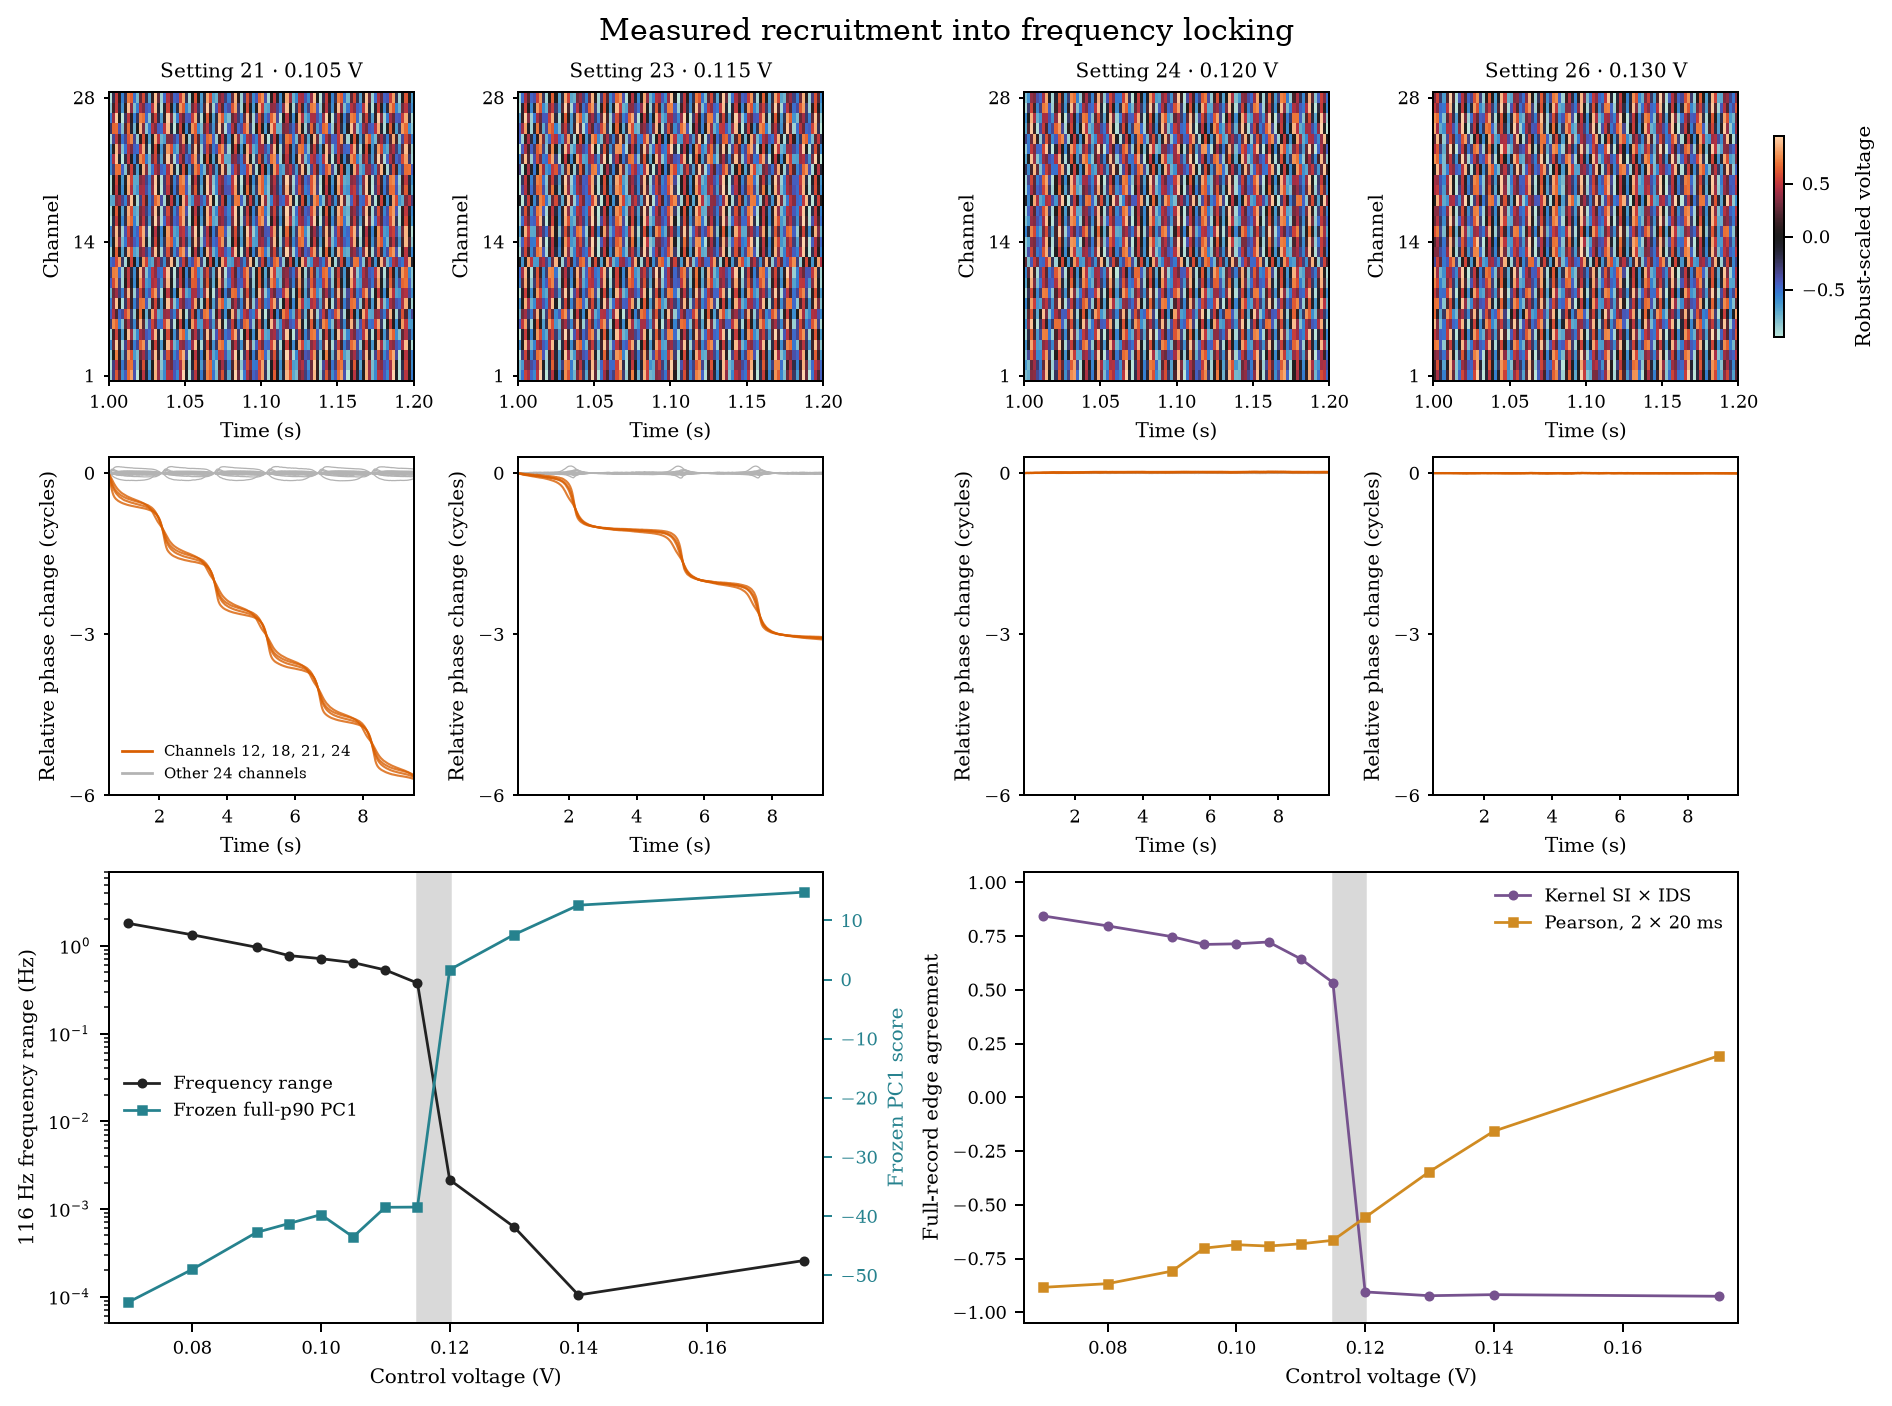

In [2]:
plot_locking(data, measured, OUT)
show('locking-composite')


## Calibrate a prominent, transparent coordinate

Use the same-estimator pair at original PC1 rank 22: $z_{\rm lag}=\operatorname{corr}_{i<j}(C_{ij}(2\,\mathrm{ms}),C_{ij}(20\,\mathrm{ms}))$, where $C_{ij}(\tau)$ averages the forward and backward Pearson correlations. This measures agreement of two edge profiles; it is not a propagation delay. Full-record recomputation matches every archived value at both lags across all 29 recordings to $5.1\times10^{-15}$.

For the common central 9 s, split the signal into 40–75, 90–140 and 150–195 Hz bands. Let $G^{(k)}_{ij}=\operatorname{cov}(x_i^{(k)},x_j^{(k)})/(\sigma_i\sigma_j)$, using **raw-record** standard deviations. A narrowband approximation gives $\widehat C_{ij}(\tau)=\sum_k\cos(2\pi f_k\tau)G^{(k)}_{ij}$; $f_k$ is the median measured band frequency. No coefficients are fitted. It reconstructs the selected z to within **0.0046** over settings 21–87.

The weaker 58 Hz component contributes only about 5–6% of channel variance, yet preserves a large contrast across pairs. As the dominant 116 Hz profile becomes more uniform, that contrast contributes more of the lag-profile variation. The chosen lags weight 58 Hz with the same sign and 116 Hz with opposite signs. This explains the gradual negative-to-positive agreement. The 58 and 116 Hz components are tightly related within each channel (2:1 phase locking); they are not evidence of independent amplitude and phase processes, and 58 Hz is not asserted to be the true fundamental.

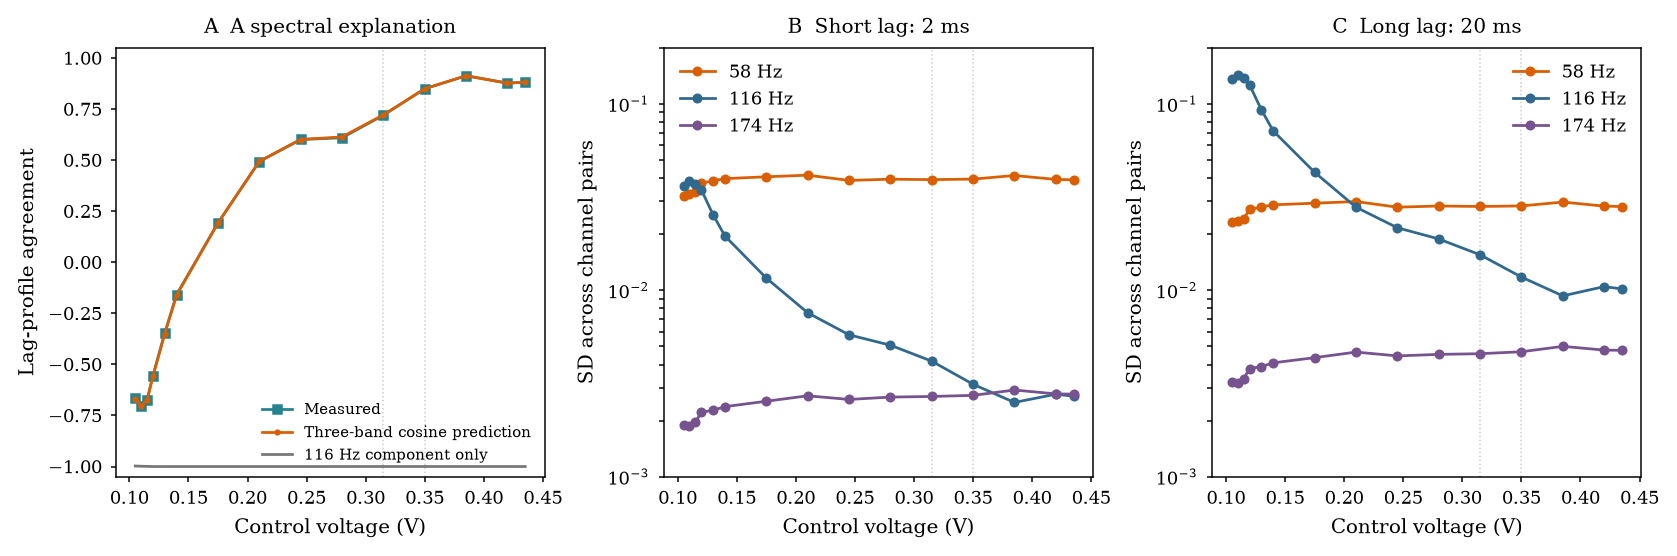

Maximum |predicted − observed z|: 0.00456


In [3]:
plot_decomposition(measured, OUT)
show('spectral-explanation')
reconstruction = measured['reconstruction'].pivot(index='step', columns='variant', values='z')
print('Maximum |predicted − observed z|:', f"{(reconstruction['Cosine prediction']-reconstruction.Raw).abs().max():.5f}")


## Different organisation at the same mean linear strength

Settings 63 and 70 have central-record mean Pearson **0.919662 and 0.919659**, but $z_{\rm lag}=\mathbf{0.720}$ and $\mathbf{0.850}$. The 58 Hz component has two nearly opposite phase groups: 19:9 versus 14:14. Both are phase coherent; their first-harmonic concentration changes .361→.019 while the second-harmonic concentration stays high (.982→.994). Group membership is unchanged across three 58 Hz bands and both record halves.

Matrices show cosine phase alignment, with scales matched across settings **within each band**; the 116 Hz colour scale is expanded. Scatterplots show the actual central-record lagged Pearson profiles, coloured by the measured 58 Hz groups. The separation persists in both halves and all single-channel edge deletions. These are sensitivity checks, not independent replicates or confidence intervals. Group balance and within-group phase spread both differ, so z is an organisation descriptor rather than a unique group-size estimator. Only mean Pearson is matched; other strength summaries can contain this information.

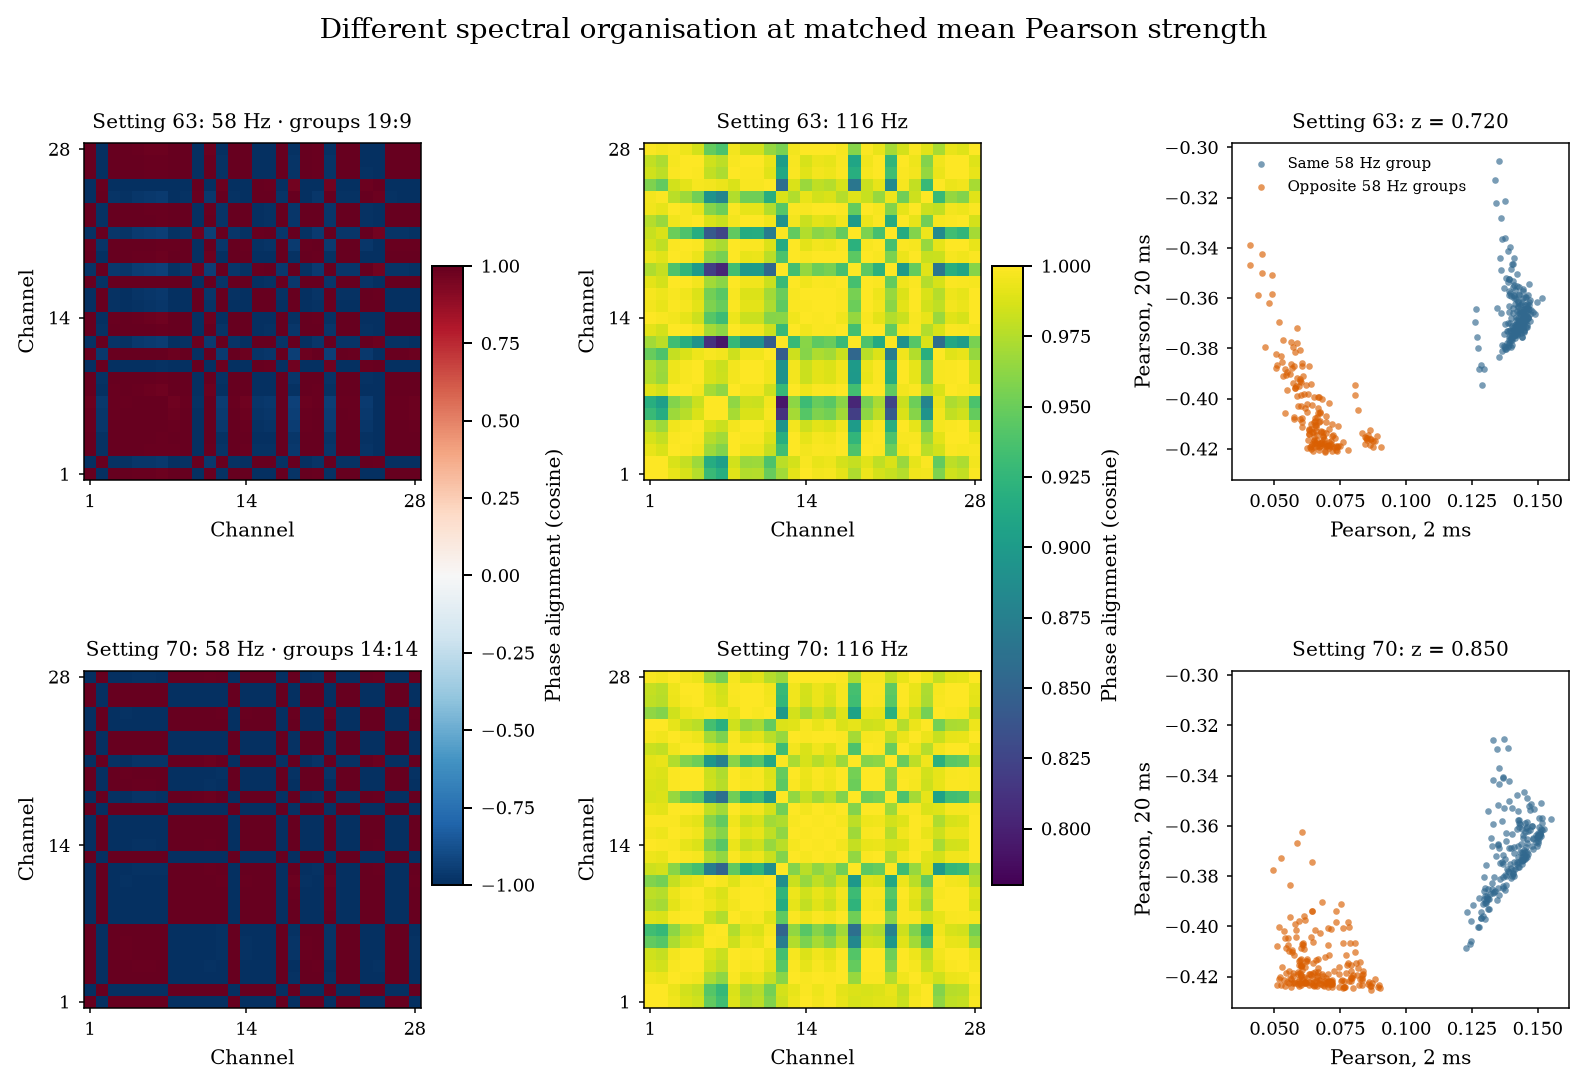

,mean_pearson,z,half_1,half_2,delete_min,delete_max,mean_R116
step,,,,,,,
63,0.919662,0.720220,0.713519,0.727230,0.703173,0.782252,0.987090
70,0.919659,0.849657,0.849640,0.849659,0.836797,0.874624,0.990845


In [4]:
plot_matched(data, measured, OUT)
show('matched-strength-organisation')
matched = measured['reconstruction'].query("variant == 'Raw' and step in [63,70]").set_index('step')
physical = measured['physical'].set_index('step')
matched = matched[['mean_pearson','z','half_1','half_2','delete_min','delete_max']].copy()
matched['mean_R116'] = physical.loc[matched.index, 'mean_R116']
display(matched.round(6))


## Controlled calibration: three ways the profiles can reorganise

Use $x_i=\cos\psi_i+a s_i\cos(\psi_i/2)+b s_i\cos(3\psi_i/2)$, with $\psi_i=2\pi116t+\phi_i+2\pi\delta_i t$ and balanced $s_i\in\{-1,1\}$ groups. Default $a=.24$, $b=.075$, SD$(\phi)=.2$ rad. Eight fixed random phase layouts are reused across interventions; lines show their mean and shading their min–max. Vary phase-offset spread, weaker-component amplitude (holding $b/a$ fixed), or coherent-channel count (the rest drift by .35 Hz). This is a compact signal control, not a fitted model of the hardware.

For fully locked signals, the exact infinite-time profile is

$$C_{ij}(\tau)=\frac{\cos(\omega\tau)\cos\Delta\phi_{ij}+a^2\cos(\omega\tau/2)s_is_j\cos(\Delta\phi_{ij}/2)+b^2\cos(3\omega\tau/2)s_is_j\cos(3\Delta\phi_{ij}/2)}{1+a^2+b^2}.$$

Changing the weaker components moves z from approximately −1 to +.93 while the carrier phases and mean carrier coordination remain fixed. Phase-offset spread and recruitment also change z: retain the calibrated name **lag-profile / spectral organisation**, without requiring it to isolate one physical mechanism. All profiles in this panel have finite spread; numerical-zero profiles would be undefined.

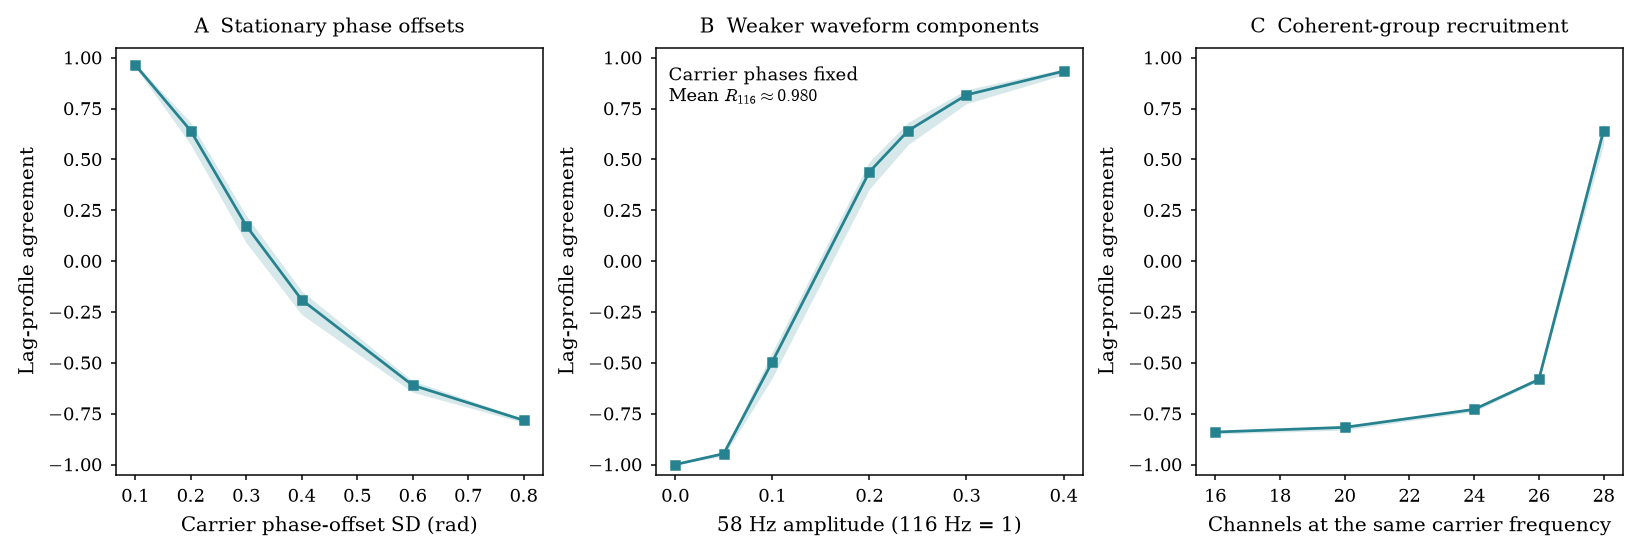

,z,mean_pearson,mean_R116,mean_PLV116
level,,,,
0.0,-1.0000,0.9593,0.9802,1.0
0.4,0.9336,0.8105,0.9802,1.0


In [5]:
plot_controls(controls, OUT)
show('controlled-calibration')
a = controls.query("family == 'amplitude' and level in [0,.4]").groupby('level')[['z','mean_pearson','mean_R116','mean_PLV116']].mean()
display(a.round(4))


**Retain two useful findings.** The measured 23→24 locking event is a defensible exploratory transition demonstration; the original representation makes its channel-level explanation visible. The selected lag-profile coordinate supplies a complementary character axis: it describes the relative organisation of spectral dependence patterns and distinguishes measured states with the same mean Pearson strength. Neither finding requires a new coupling law or causal identification. Selection is exploratory within one sweep; the band decomposition uses measured covariances and is explanatory evidence, not an independent test.

In [6]:
membership_mismatches = int(measured['sensitivities'].membership_mismatches.max())
assert membership_mismatches == 0
receipt = write_receipt(data, measured, formula_error, OUT, RUN)
summary = {
    'selected_feature': ['corr_pearson_tau-1', 'corr_pearson_tau-10'],
    'original_pc1_rank': 22,
    'maximum_cosine_prediction_z_error': float((reconstruction['Cosine prediction']-reconstruction.Raw).abs().max()),
    'matched_settings_central9s': matched.reset_index().to_dict(orient='records'),
    'locking_contrast': measured['physical'].query('step in [21,23,24,26]').to_dict(orient='records'),
    'profile_floor_is_numerical_only': 1e-8,
    'maximum_group_membership_mismatches': membership_mismatches,
    'minimum_control_profile_sd': float(controls[['sd_short','sd_long']].min().min()),
    'scope': 'Exploratory selected sweep; no new feature fitting or physical replication.'}
(OUT/'summary.json').write_text(json.dumps(summary, indent=2)+'\n')
print(f"Verified 29 archived lag-matrix pairs: max error {receipt['cached_lag_replay_max_abs_error']:.2g}")
print(f"Verified analytic periodic control: max error {formula_error:.2g}")
print('Reproduction: execute this notebook from the repository environment. Tables and vector figures: results/hardware-pilot-261012/calibrate/')


Verified 29 archived lag-matrix pairs: max error 5e-15
Verified analytic periodic control: max error 1.3e-13
Reproduction: execute this notebook from the repository environment. Tables and vector figures: results/hardware-pilot-261012/calibrate/


## Small-world transfer: the spectral interpretation persists

Freeze the Pearson 2×20 ms feature, three bands, filter and central-9-s window. Twelve preset settings plus four selected **only from frequency dispersion** give 16 recordings from the [small-world sweep](https://zenodo.org/records/17451530). All pass the full-duration T=5000 audit; T=10000 changes z by at most **.0042**. This fixed-feature transfer required no PCA or full-p90 extraction.

The unchanged explanation meets both targets (edge-profile r≥.95; |Δz|≤.05) in **15/16 recordings**; median |Δz|=.0054, with z spanning −.953 to +.900. Carrier frequency range falls **.586→.000656 Hz at 31→34**, a different control interval from ER. Grey bands mark this observed interval; voltage axes are logarithmic above .05 V and linear below.

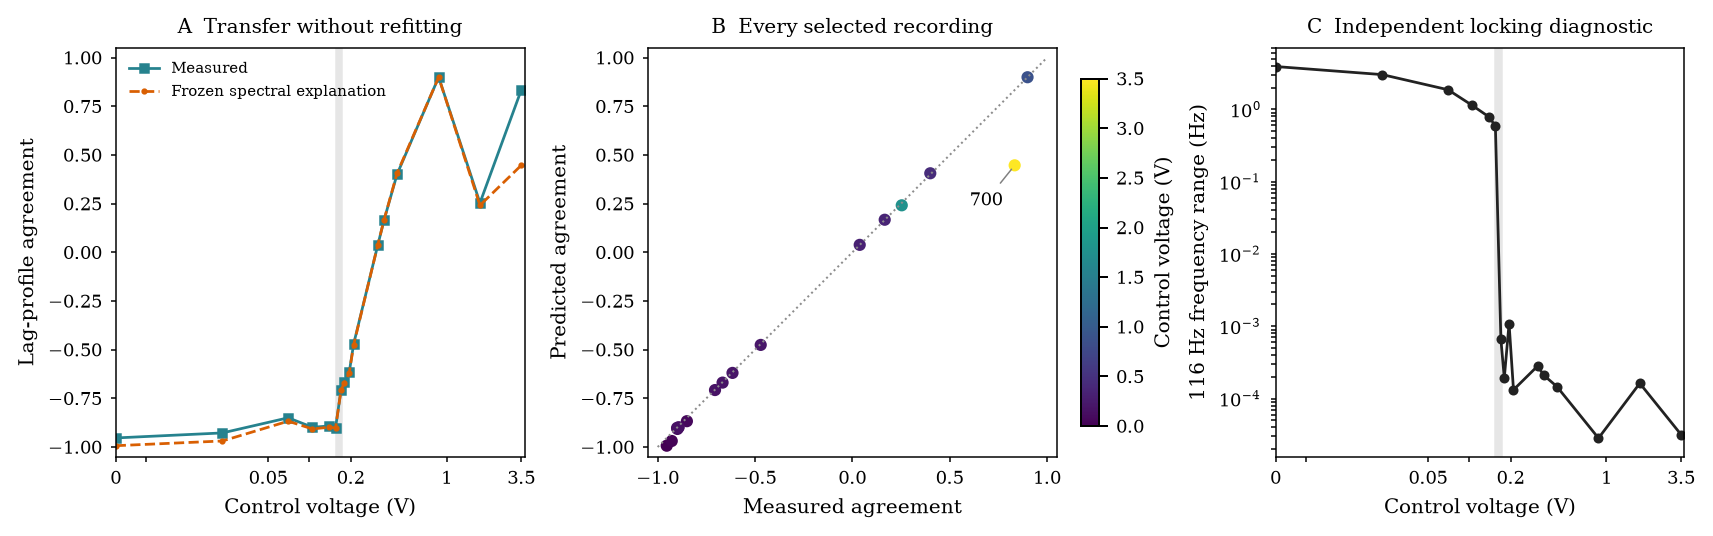

Reconstruction targets: 15/16; median z error 0.0054; maximum T5000–T10000 change 0.0042


In [7]:
from research.empirical.hardware_pilot.transfer_hardware_pilot import plot_transfer
TRANSFER = RUN.parent/'transfer-sw-261014'
transfer_summary = json.loads((TRANSFER/'summary.json').read_text())
transfer_frame = pd.read_csv(TRANSFER/'features.csv')
illustrative_pair = plot_transfer(TRANSFER)
display(Image(filename=str(TRANSFER/'transfer-summary.png')))
print(f"Reconstruction targets: {transfer_summary['reconstruction_targets_met']}/{transfer_summary['records']}; "
      f"median z error {transfer_summary['median_z_error']:.4f}; "
      f"maximum T5000–T10000 change {transfer_summary['max_resolution_z_difference']:.4f}")

A **modest strength-matched contrast** survives: settings 14/28 have mean Pearson .2005/.1987 but z=−.850/−.892. Both halves and all channel deletions separate them. This misses the ambitious .10 target but exceeds the observed sensitivity variation. The 116 Hz covariance profile becomes more heterogeneous (SD .430→.503), while the 58 Hz profile changes little (.0307→.0319); the frozen explanation predicts the feature's direction. Only mean Pearson is matched.

The large 350/700 contrast is not retained as confirmation: 700 fails reconstruction (error .387), with almost-collapsed short-lag spread (.000615). Its weaker-band spectral peaks are approximately 69/163 Hz in the native-resolution PSD. No bands or frequency rules were retuned. Below are **all** pairs within the frozen .01 mean-Pearson caliper; the smaller robust example is labelled explicitly.

,step_a,step_b,mean_pearson_difference,delta_z,working_contrast_target,both_reconstructed
0,14,28,-0.0018,-0.0421,False,True
1,34,36,-0.0004,0.0388,False,True
2,350,700,0.0088,0.5800,True,False


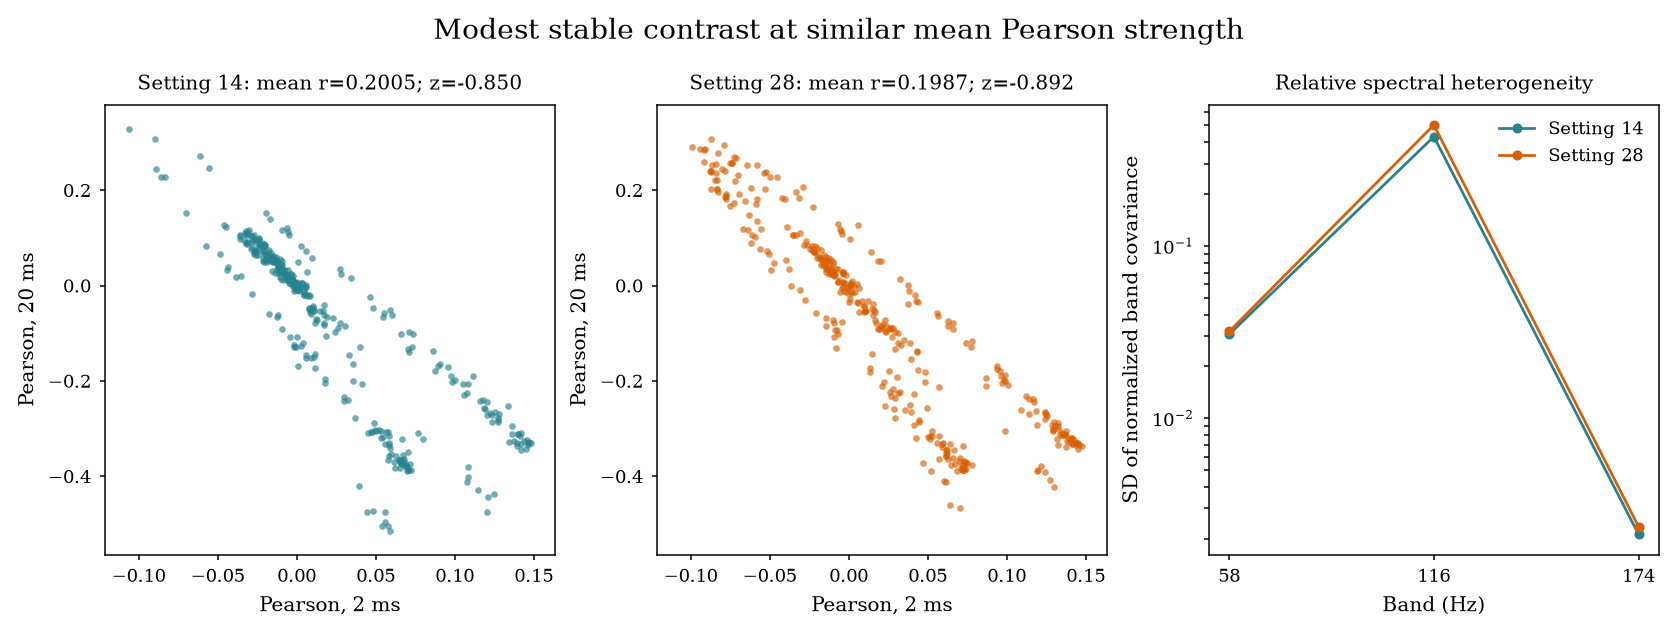

In [8]:
transfer_pairs = pd.read_csv(TRANSFER/'matched-pairs.csv')
display(transfer_pairs[['step_a','step_b','mean_pearson_difference','delta_z',
                        'working_contrast_target','both_reconstructed']].round(4))
if illustrative_pair is not None:
    display(Image(filename=str(TRANSFER/'transfer-matched-contrast.png')))
# Full selected panel, provenance and physical-only selection remain in TRANSFER.
assert len(transfer_frame) == 16
assert transfer_summary['source_revision'] == '8cf7640'
assert transfer_summary['bands_hz'] == {'58':[40,75], '116':[90,140], '174':[150,195]}

## Updated full-p90: ER fit, small-world projection

All 45 records validate under the same r9 implementation, retaining 28 channels, T=5000 and every dyad. Centre-only PCA uses 27,698 complete, varying ER features; **PC1 explains 45.21%** and all 16 small-world records project without imputation. The largest adjacent PC1 changes occur at ER 23→24 and SW 31→34, matching their separately measured locking intervals. Shading marks those physical intervals, not fitted critical points.

Nineteen of the 20 largest weights pair correlation variants. Removing every such feature preserves PC1 scores (|r| = .9976 ER/.9958 SW); leave-one-ER-record loading cosine stays ≥ .9956. This is stable geometry for the selected sweeps. Uneven control sampling and nonmonotonic post-locking scores preclude calling PC1 a universal order parameter.

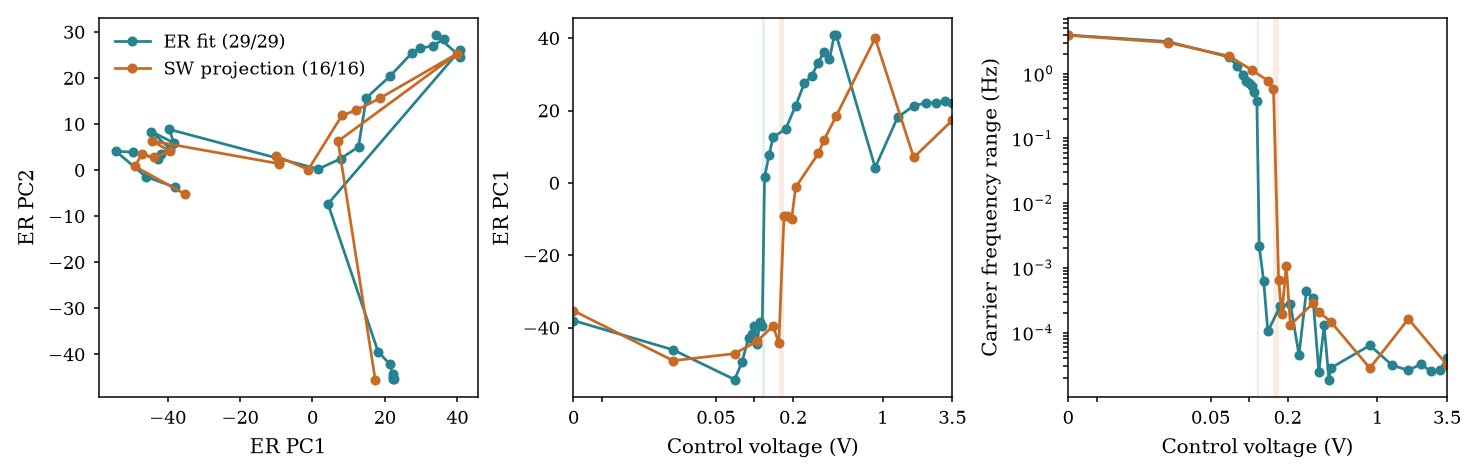

ER PC1: 45.2% variance; 27,698 features
Unprojectable records: []
Correlation-family exclusion: {'ER': {'paired_records': 29, 'absolute_pc1_correlation': 0.9976086837690038}, 'SW': {'paired_records': 16, 'absolute_pc1_correlation': 0.995809813563325}}


In [9]:
from research.empirical.hardware_pilot.full_p90_analysis import (
    analyse, rank_loadings, contrast_contributions, edge_diagnostics,
    plot_overview, plot_loadings, plot_edge_contrast, save_figure, carrier_groups, partition_covariance, LAG_PAIR)
import matplotlib.pyplot as plt
FULL = RUN.parent/'full-p90-r9-261014'
complete_tables = list((FULL/'mpis').glob('*/*/meta.json'))
full = None
if len(complete_tables) == 45:
    full = analyse(FULL)
    bank, models = full['bank'], full['models']
    assert not full['summary']['benchmark_archive_parity_failures']
    FIG = FULL/'analysis'
    def full_figure(fig, name):
        save_figure(fig, FIG, name)
        plt.close(fig)
        display(Image(filename=str(FIG/f'{name}.png')))
    full_figure(plot_overview(bank, models, full['benchmark']), 'er-fit-sw-projection')
    print(f"ER PC1: {100*models['er'].variance_ratio[0]:.1f}% variance; {len(models['er'].features):,} features")
    print('Unprojectable records:', full['summary']['models']['er']['unprojectable'])
    print('Correlation-family exclusion:', full['summary']['correlation_exclusion_sensitivity'])
else:
    print(f'Tables present: {len(complete_tables)}/45. Full provenance/coverage validation and interpretation remain pending.')


,rank,spi_a,spi_b,weight
0,1,corr_pearson_tau-1,corr_kendall_tau-10,0.022904
1,2,corr_spearman_tau-1,corr_kendall_tau-10,0.022758
2,3,corr_spearman_tau-3,corr_kendall_tau-5,0.022678
3,4,corr_spearman_tau-3,corr_kendall_tau-10,-0.022475
4,5,corr_pearson_tau-1,corr_kendall_tau-5,-0.022431
5,6,corr_pearson_tau-1,corr_kendall_tau-4,-0.022413
6,7,corr_spearman_tau-1,corr_kendall_tau-4,-0.022255
7,8,corr_spearman_tau-1,corr_kendall_tau-5,-0.022250


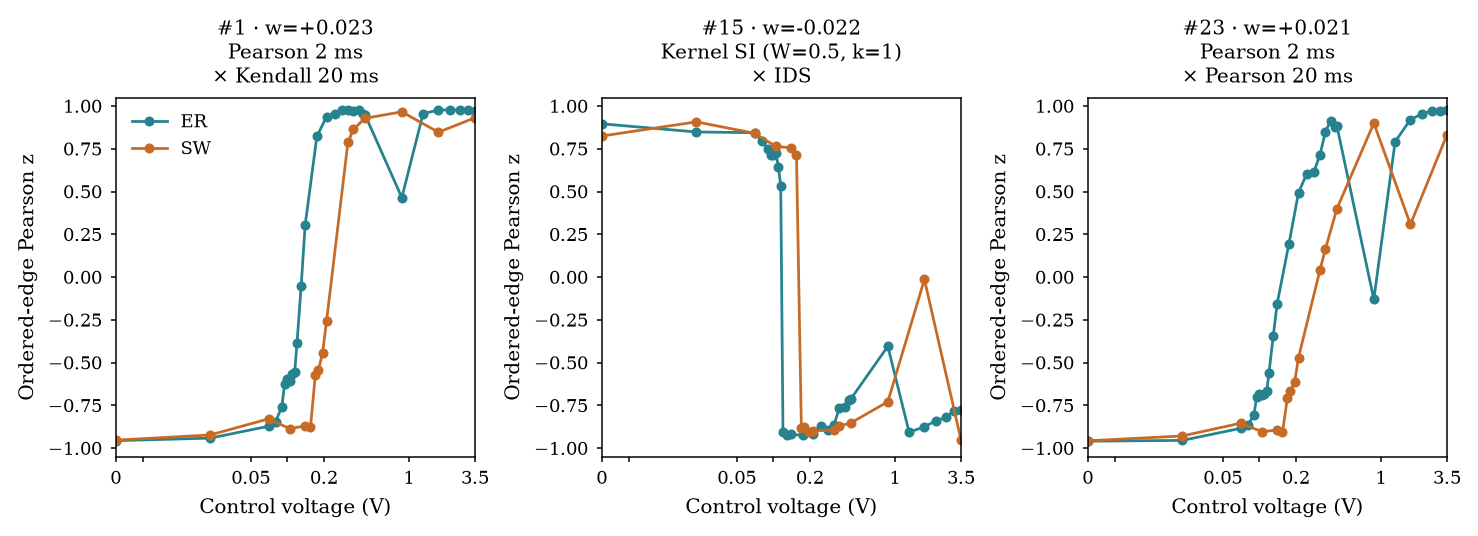

Loading rank is exploratory selection. Cached channel deletion is a sensitivity check, not an estimator refit or confidence interval.


In [10]:
if full is not None:
    loadings = rank_loadings(bank, models['er'])
    display(loadings.head(8)[['rank','spi_a','spi_b','weight']])
    lag_index = next(i for i,s in enumerate(bank.schema) if {s.spi_a,s.spi_b} == set(LAG_PAIR))
    other = loadings.loc[~loadings.both_correlation]
    candidates = list(dict.fromkeys([int(loadings.iloc[0].feature_index),
                                     *other.feature_index.head(1).astype(int).tolist(), lag_index]))
    full_figure(plot_loadings(bank, models['er'], candidates), 'leading-feature-candidates')
    for feature in candidates:
        edge_diagnostics(bank, feature).to_csv(FIG/f'edge-diagnostics-{feature}.csv', index=False)
    print('Loading rank is exploratory selection. Cached channel deletion is a sensitivity check, not an estimator refit or confidence interval.')


### A transferred profile reorganisation at locking

**Kernel stochastic interaction × IDS** is the highest-weight non-correlation pair (rank 15, w=−.02168) and the largest individual coordinate contribution to both PC1 jumps. Edge agreement changes **+.534→−.905 in ER** and **+.712→−.881 in small-world**; all single-channel edge deletions preserve the sign reversal, with appreciable profile spread.

[IDS](https://github.com/aradha/interdependence_scores) measures contemporaneous dependence using nonlinear kernel features. Stochastic interaction compares separate versus joint conditional entropies and includes both temporal and equal-time dependence ([Oizumi et al., §II.4](https://arxiv.org/html/1510.04455#S2.SS4)); a pure causal or predictive interpretation would be incorrect. Black points below are the same dyads selected **before** locking by central-9-s carrier PLV > .95: 280 ER and 99 small-world dyads. Their agreement is already negative before locking. Exact within/between-group covariance accounting shows where the global reversal comes from; it does not establish causal mediation.

Retain this as an operational descriptor of profile organisation accompanying recruitment into coherent dynamics. Gaussian/Kozachenko SI lose positive agreement too, but do not reproduce the strong negative reversal. The stronger semantic claim therefore remains conditional on the fixed kernel estimator; bandwidth and half-record robustness have not been established for this candidate.

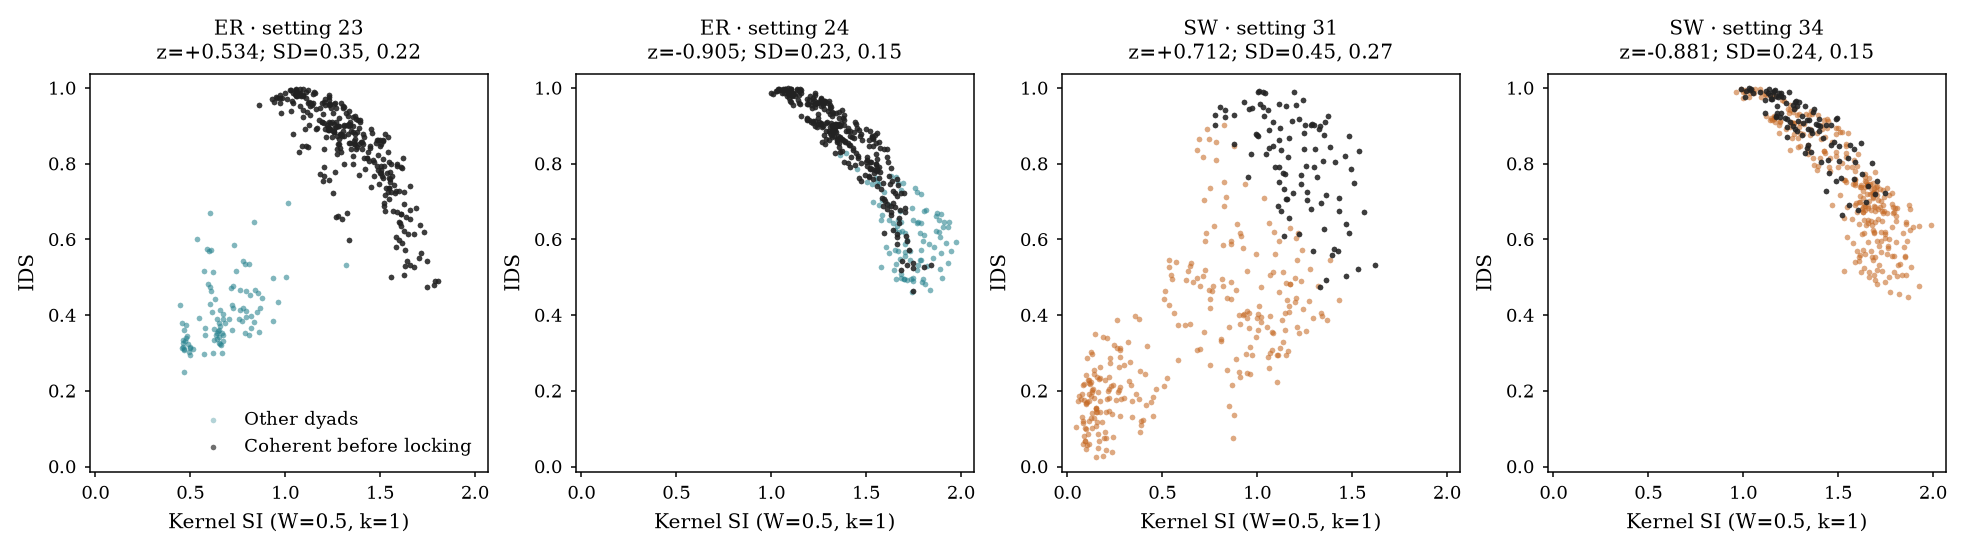

,topology,step,z,within_coherent,within_other,between
0,ER,23,0.534,-0.198,0.020,0.712
1,ER,24,-0.905,-0.401,-0.035,-0.469
2,SW,31,0.712,-0.030,0.295,0.447
3,SW,34,-0.881,-0.099,-0.600,-0.182


,records,reconstructed,median_z_error,max_z_error
topology,,,,
ER,29,25,0.002754,0.356391
SW,16,15,0.005359,0.386905


,topology,step,z,predicted_z,z_error,sd_short,sd_long
22,ER,175,-0.10379,-0.16044,0.05666,0.00211,0.00244
23,ER,262,0.79338,0.43699,0.35639,0.00116,0.00168
24,ER,350,0.92034,0.80715,0.11318,0.00110,0.00148
25,ER,437,0.95539,0.80257,0.15282,0.00102,0.00133
44,SW,700,0.83391,0.44700,0.38690,0.00061,0.00097


In [11]:
if full is not None:
    row_index = {(r['topology'],r['step']):i for i,r in enumerate(bank.rows)}
    transition_rows = [row_index[k] for k in [('ER',23),('ER',24),('SW',31),('SW',34)]]
    candidate = int(other.iloc[0].feature_index) if len(other) else candidates[0]
    groups = carrier_groups(bank)
    full_figure(plot_edge_contrast(bank, candidate, transition_rows, groups), 'candidate-original-edges')
    mixture = partition_covariance(bank, candidate, transition_rows, groups)
    mixture.to_csv(FIG/'candidate-covariance-partition.csv', index=False)
    display(mixture[['topology','step','z','within_coherent','within_other','between']].round(3))
    for topology, a, b in [('ER',23,24),('SW',31,34)]:
        left, right = row_index[topology,a], row_index[topology,b]
        if np.isfinite(models['er'].project(bank.z)[[left,right],0]).all():
            contrast_contributions(bank, models['er'], left, right).head(20).to_csv(
                FIG/f'{topology.lower()}-transition-contributions.csv', index=False)
    benchmark = full['benchmark']
    display(benchmark.groupby('topology').agg(
        records=('name','size'), reconstructed=('reconstruction_target_met','sum'),
        median_z_error=('z_error','median'), max_z_error=('z_error','max')))
    display(benchmark.loc[~benchmark.reconstruction_target_met,
        ['topology','step','z','predicted_z','z_error','sd_short','sd_long']].round(5))


The best-calibrated character axis remains **Pearson 2 ms × Pearson 20 ms lag-profile agreement** (rank 23, w=+.02123): it describes how spectral dependence patterns combine across pairs. The unchanged three-band explanation passes 40/45 records, including the existing scalar-strength-matched examples. Failures are ER 175/262/350/437 and SW 700, where short-lag profile SD is only .0006–.0021; fine differences in almost-uniform profiles materially affect z. These failures restrict the explanation's applicability. Neither the calibrated lag feature nor the SI×IDS contrast isolates a unique physical mechanism or removes every form of strength information.